# ECG-Guard — Final Model Evaluation & Deployment

**Project:** Four-class ECG heartbeat classification  
**Selected model:** ECG-Guard V3 (1D CNN)  
**Input:** One already-preprocessed heartbeat containing 77 samples  
**Output classes:** Normal, Supraventricular, Ventricular, Fusion

This is the cleaned final notebook. It removes duplicate experiments, the reduced test-set workflow, unused RR-feature extraction, and the unsuccessful full-data training experiment.

## Model selection

The recorded comparison on the **3,000-sample stratified validation subset** selected **ECG-Guard V3**. The final notebook below restores the complete original validation and test sets for calibration and evaluation.

| Model | Subset accuracy | Subset balanced accuracy | Subset Macro F1 |
|---|---:|---:|---:|
| ECG-Guard V3 | 65.97% | 55.38% | **45.81%** |
| ECG-Guard V4 | 63.57% | 57.96% | 45.56% |

The separate full-data experiment was not retained because it showed substantial training/validation overfitting.

The recorded V3 result on the **complete, original 44,534-beat test set** was:

- Accuracy: **78.08%**
- Balanced accuracy: **59.21%**
- Macro F1: **40.73%**

The test set is naturally imbalanced. Accuracy must therefore be interpreted alongside balanced accuracy, Macro F1, and per-class results. These results do not establish clinical readiness.


In [ ]:
# 1. IMPORTS AND ENVIRONMENT

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from IPython.display import display
from google.colab import drive

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

drive.mount("/content/drive")

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


Mounted at /content/drive
TensorFlow: 2.21.0
GPU devices: []


In [ ]:
# 2. PROJECT PATHS AND CLASS DEFINITIONS

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ECG_Guard_Dataset_V2/processed_v3"
)

assert OUTPUT_DIR.exists(), f"Dataset directory not found: {OUTPUT_DIR}"

CLASS_NAMES = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion"
]

NUM_CLASSES = len(CLASS_NAMES)
INPUT_LENGTH = 77

BALANCED_TRAIN_X = OUTPUT_DIR / "X_train_balanced_v3.npy"
BALANCED_TRAIN_Y = OUTPUT_DIR / "y_train_balanced_v3.npy"
VALIDATION_X = OUTPUT_DIR / "X_validation_v3.npy"
VALIDATION_Y = OUTPUT_DIR / "y_validation_v3.npy"
TEST_X = OUTPUT_DIR / "X_test_v3.npy"
TEST_Y = OUTPUT_DIR / "y_test_v3.npy"

print("Project directory:", OUTPUT_DIR)


Project directory: /content/drive/MyDrive/ECG_Guard_Dataset_V2/processed_v3


In [ ]:
# 3. LOAD THE BALANCED TRAINING SET AND COMPLETE VALIDATION/TEST SETS

X_train = np.load(BALANCED_TRAIN_X)
y_train = np.load(BALANCED_TRAIN_Y).astype(np.int32)

# Keep the complete original validation and test sets.
# Do not use the old 3,000-sample reduced subsets for final evaluation.
X_val = np.load(VALIDATION_X)
y_val = np.load(VALIDATION_Y).astype(np.int32)

X_test = np.load(TEST_X)
y_test = np.load(TEST_Y).astype(np.int32)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (12000, 77) (12000,)
Validation: (40663, 77) (40663,)
Testing: (44534, 77) (44534,)


In [ ]:
# 4. LOAD METADATA AND VERIFY PATIENT-INDEPENDENT SPLITS

metadata_df = pd.read_csv(
    OUTPUT_DIR / "beat_metadata_v3.csv",
    low_memory=False,
    dtype={"record": str, "group_id": str}
)

train_metadata = pd.read_csv(
    OUTPUT_DIR / "balanced_training_metadata_v3.csv",
    low_memory=False,
    dtype={"record": str, "group_id": str}
)

def get_split_metadata(split_name):
    frame = metadata_df[
        metadata_df["split"].astype(str).str.lower() == split_name.lower()
    ].copy()

    frame["split_index"] = pd.to_numeric(
        frame["split_index"], errors="raise"
    )

    return (
        frame.sort_values("split_index")
        .reset_index(drop=True)
    )

val_metadata = get_split_metadata("validation")
test_metadata = get_split_metadata("test")

assert len(train_metadata) == len(y_train)
assert len(val_metadata) == len(y_val)
assert len(test_metadata) == len(y_test)

assert np.array_equal(
    pd.to_numeric(train_metadata["label"], errors="raise")
    .astype(int).to_numpy(),
    y_train
), "Training metadata labels are not aligned."

assert np.array_equal(
    pd.to_numeric(val_metadata["label"], errors="raise")
    .astype(int).to_numpy(),
    y_val
), "Validation metadata labels are not aligned."

assert np.array_equal(
    pd.to_numeric(test_metadata["label"], errors="raise")
    .astype(int).to_numpy(),
    y_test
), "Test metadata labels are not aligned."

train_groups = set(train_metadata["group_id"].astype(str))
val_groups = set(val_metadata["group_id"].astype(str))
test_groups = set(test_metadata["group_id"].astype(str))

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("Metadata and labels are aligned.")
print("Patient-independent split verification: PASS")
print("Train/validation/test patient overlap: 0")


Metadata and labels are aligned.
Patient-independent split verification: PASS
Train/validation/test patient overlap: 0


In [ ]:
# 5. STANDARDISE INPUT DIMENSIONS AND CHECK DATA QUALITY

def fix_ecg_dimensions(X, name):
    X = np.asarray(X, dtype=np.float32)

    while X.ndim > 3 and X.shape[-1] == 1:
        X = np.squeeze(X, axis=-1)

    if X.ndim == 2 and X.shape[1] == INPUT_LENGTH:
        X = X[..., np.newaxis]

    elif X.ndim == 3 and X.shape[1:] == (1, INPUT_LENGTH):
        X = np.transpose(X, (0, 2, 1))

    if X.ndim != 3 or X.shape[1:] != (INPUT_LENGTH, 1):
        raise ValueError(
            f"{name} has shape {X.shape}; expected (N, 77, 1)."
        )

    if not np.isfinite(X).all():
        raise ValueError(f"{name} contains NaN or infinite values.")

    return np.ascontiguousarray(X, dtype=np.float32)

X_train = fix_ecg_dimensions(X_train, "X_train")
X_val = fix_ecg_dimensions(X_val, "X_val")
X_test = fix_ecg_dimensions(X_test, "X_test")

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

print("Final tensor shapes:")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Final tensor shapes:
Train: (12000, 77, 1)
Validation: (40663, 77, 1)
Test: (44534, 77, 1)


In [ ]:
# 6. CLASS DISTRIBUTION AUDIT

def distribution_table(labels, split_name):
    counts = np.bincount(labels, minlength=NUM_CLASSES)
    return pd.DataFrame({
        "Split": split_name,
        "Class": CLASS_NAMES,
        "Samples": counts,
        "Percentage": counts / counts.sum() * 100
    })

distribution_df = pd.concat(
    [
        distribution_table(y_train, "Training"),
        distribution_table(y_val, "Validation"),
        distribution_table(y_test, "Test")
    ],
    ignore_index=True
)

display(
    distribution_df.style.format({"Percentage": "{:.2f}%"})
)


,Split,Class,Samples,Percentage
0,Training,Normal,3000,25.00%
1,Training,Supraventricular,3000,25.00%
2,Training,Ventricular,3000,25.00%
3,Training,Fusion,3000,25.00%
4,Validation,Normal,35759,87.94%
5,Validation,Supraventricular,494,1.21%
6,Validation,Ventricular,4360,10.72%
7,Validation,Fusion,50,0.12%
8,Test,Normal,39798,89.37%
9,Test,Supraventricular,572,1.28%


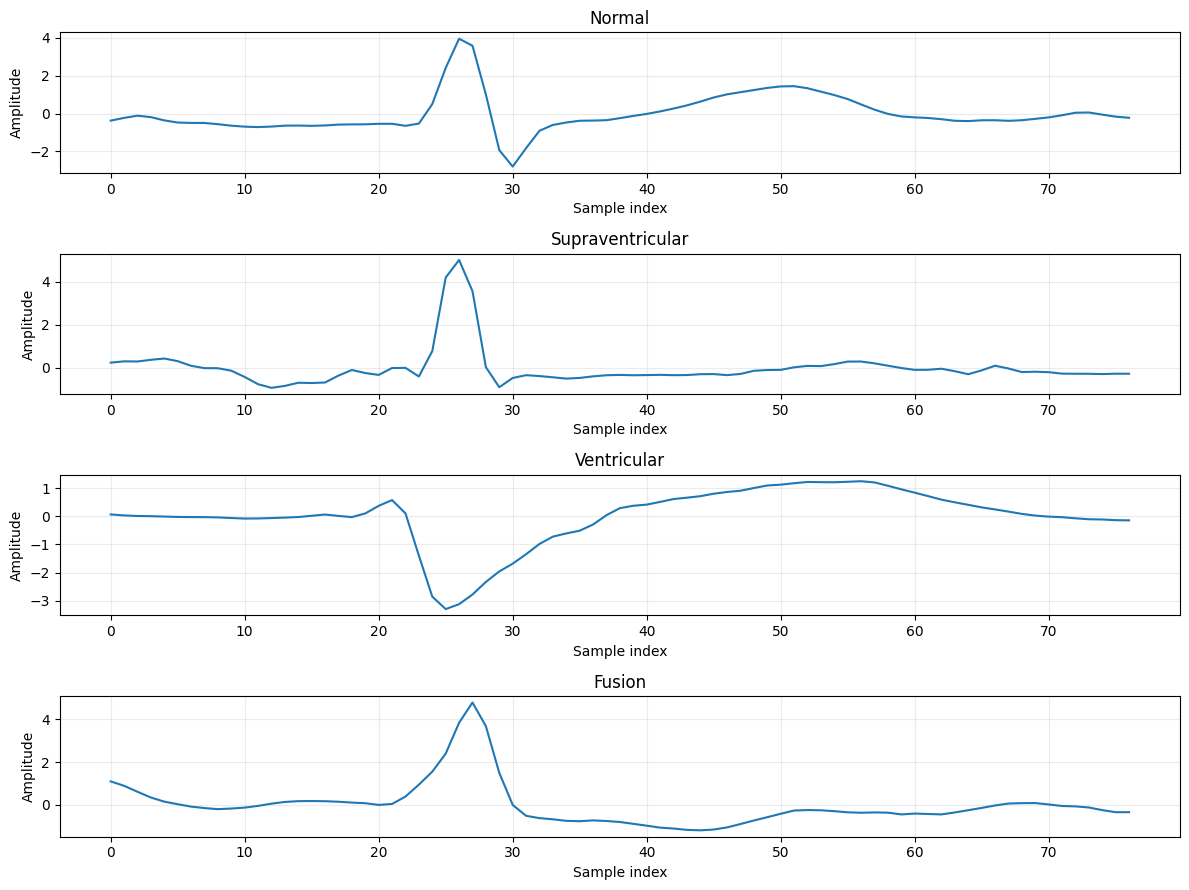

In [ ]:
# 7. VISUALISE ONE EXAMPLE BEAT FROM EACH CLASS

fig, axes = plt.subplots(4, 1, figsize=(12, 9))

for class_id, ax in enumerate(axes):
    indices = np.where(y_train == class_id)[0]
    if len(indices) == 0:
        continue

    signal = X_train[indices[0], :, 0]
    ax.plot(np.arange(INPUT_LENGTH), signal)
    ax.set_title(CLASS_NAMES[class_id])
    ax.set_xlabel("Sample index")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


## Selected model

The final application uses the saved **ECG-Guard V3** model. Its architecture is a waveform-only 1D CNN:

`Conv1D(32) → BatchNorm/ReLU → MaxPool → Conv1D(64) → BatchNorm/ReLU → MaxPool → Conv1D(128) → BatchNorm/ReLU → GlobalAveragePooling → Dense(64) → Dropout → Softmax(4)`

The RR interval features explored during development are not part of this deployed model.


In [ ]:
# 8. LOAD THE SELECTED ECG-GUARD V3 MODEL

FINAL_MODEL_PATH = OUTPUT_DIR / "ecg_guard_final.keras"
V3_MODEL_PATH = OUTPUT_DIR / "best_ecg_guard_v3.keras"

if FINAL_MODEL_PATH.exists():
    MODEL_TO_LOAD = FINAL_MODEL_PATH
elif V3_MODEL_PATH.exists():
    MODEL_TO_LOAD = V3_MODEL_PATH
else:
    raise FileNotFoundError(
        "Could not find ecg_guard_final.keras or best_ecg_guard_v3.keras "
        "in the processed_v3 Drive folder."
    )

best_model = tf.keras.models.load_model(
    str(MODEL_TO_LOAD),
    compile=False
)

print("Selected model: ECG-Guard V3")
print("Loaded from:", MODEL_TO_LOAD)
best_model.summary()


Selected model: ECG-Guard V3
Loaded from: /content/drive/MyDrive/ECG_Guard_Dataset_V2/processed_v3/ecg_guard_final.keras


Model: "ECG_Guard_CNN_V3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ecg_input (InputLayer)          │ (None, 77, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 77, 32)         │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 77, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 77, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 38, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 38, 64)         │        10,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 38, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 38, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 19, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 19, 128)        │        24,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 19, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 19, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,452 (173.64 KB)

 Trainable params: 44,004 (171.89 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# 9. SELECT CALIBRATION USING VALIDATION DATA ONLY

# The model was trained on a balanced 25%-per-class training set.
# The validation set retains the original natural class distribution.
val_prob_raw = best_model.predict(
    X_val,
    batch_size=512,
    verbose=1
)

train_counts = np.bincount(y_train, minlength=NUM_CLASSES)
val_counts = np.bincount(y_val, minlength=NUM_CLASSES)

train_prior = train_counts / train_counts.sum()
val_prior = val_counts / val_counts.sum()

prior_ratio = val_prior / np.maximum(train_prior, 1e-8)

print("Training prior:", train_prior)
print("Validation prior:", val_prior)

calibration_rows = []

for alpha in np.linspace(0, 1.5, 61):
    adjusted = (
        val_prob_raw *
        np.power(prior_ratio, alpha)[np.newaxis, :]
    )

    adjusted /= np.maximum(
        adjusted.sum(axis=1, keepdims=True),
        1e-12
    )

    pred = np.argmax(adjusted, axis=1)

    calibration_rows.append({
        "Alpha": float(alpha),
        "Accuracy": accuracy_score(y_val, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val, pred),
        "Macro F1": f1_score(
            y_val,
            pred,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )
    })

calibration_df = pd.DataFrame(calibration_rows)

# Prefer settings meeting the validation accuracy target, then
# maximise balanced accuracy and Macro F1 among those settings.
eligible = calibration_df[calibration_df["Accuracy"] >= 0.82]

if eligible.empty:
    eligible = calibration_df[calibration_df["Accuracy"] >= 0.80]

if eligible.empty:
    selected = calibration_df.sort_values(
        ["Accuracy", "Balanced Accuracy", "Macro F1"],
        ascending=False
    ).iloc[0]
else:
    selected = eligible.sort_values(
        ["Balanced Accuracy", "Macro F1", "Accuracy"],
        ascending=False
    ).iloc[0]

SELECTED_ALPHA = float(selected["Alpha"])

print("\n========== VALIDATION-SELECTED CALIBRATION ==========")
print("Alpha:", SELECTED_ALPHA)
print("Validation accuracy:", round(selected["Accuracy"], 4))
print("Validation balanced accuracy:", round(selected["Balanced Accuracy"], 4))
print("Validation Macro F1:", round(selected["Macro F1"], 4))

display(
    calibration_df.sort_values(
        "Accuracy", ascending=False
    ).head(10).round(4)
)


80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step
Training prior: [0.25 0.25 0.25 0.25]
Validation prior: [0.87939896 0.01214864 0.10722278 0.00122962]

========== VALIDATION-SELECTED CALIBRATION ==========
Alpha: 0.17500000000000002
Validation accuracy: 0.8232
Validation balanced accuracy: 0.5307
Validation Macro F1: 0.4768


,Alpha,Accuracy,Balanced Accuracy,Macro F1
60,1.500,0.9601,0.4543,0.4606
59,1.475,0.9597,0.4552,0.4603
58,1.450,0.9591,0.4560,0.4596
57,1.425,0.9581,0.4567,0.4586
56,1.400,0.9571,0.4569,0.4574
55,1.375,0.9561,0.4574,0.4563
54,1.350,0.9551,0.4581,0.4553
53,1.325,0.9542,0.4584,0.4543
52,1.300,0.9531,0.4591,0.4532
51,1.275,0.9518,0.4595,0.4519


In [ ]:
# 10. FINAL EVALUATION ON THE COMPLETE, UNTOUCHED TEST SET

# Raw predictions
test_prob_raw = best_model.predict(
    X_test,
    batch_size=512,
    verbose=1
)
y_test_raw = np.argmax(test_prob_raw, axis=1)

# Calibrated predictions using alpha selected on validation only
test_prob_calibrated = (
    test_prob_raw *
    np.power(prior_ratio, SELECTED_ALPHA)[np.newaxis, :]
)
test_prob_calibrated /= np.maximum(
    test_prob_calibrated.sum(axis=1, keepdims=True),
    1e-12
)
y_test_calibrated = np.argmax(test_prob_calibrated, axis=1)

def metric_summary(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "macro_precision": float(
            precision_score(
                y_true, y_pred, labels=[0, 1, 2, 3],
                average="macro", zero_division=0
            )
        ),
        "macro_recall": float(
            recall_score(
                y_true, y_pred, labels=[0, 1, 2, 3],
                average="macro", zero_division=0
            )
        ),
        "macro_f1": float(
            f1_score(
                y_true, y_pred, labels=[0, 1, 2, 3],
                average="macro", zero_division=0
            )
        )
    }

raw_test_metrics = metric_summary(y_test, y_test_raw)
calibrated_test_metrics = metric_summary(y_test, y_test_calibrated)

print("Complete test samples:", len(y_test))
print("Test class counts:", np.bincount(y_test, minlength=NUM_CLASSES))

print("\nRAW V3 TEST METRICS")
for key, value in raw_test_metrics.items():
    print(f"{key}: {value:.4f}")

print("\nCALIBRATED V3 TEST METRICS")
for key, value in calibrated_test_metrics.items():
    print(f"{key}: {value:.4f}")

print("\nCALIBRATED CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_test_calibrated,
        labels=[0, 1, 2, 3],
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)


87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step
Complete test samples: 44534
Test class counts: [39798   572  4114    50]

RAW V3 TEST METRICS
accuracy: 0.7808
balanced_accuracy: 0.5921
macro_precision: 0.4034
macro_recall: 0.5921
macro_f1: 0.4073

CALIBRATED V3 TEST METRICS
accuracy: 0.8655
balanced_accuracy: 0.6011
macro_precision: 0.4065
macro_recall: 0.6011
macro_f1: 0.4245

CALIBRATED CLASSIFICATION REPORT
                  precision    recall  f1-score   support

          Normal     0.9774    0.8737    0.9227     39798
Supraventricular     0.0012    0.0017    0.0014       572
     Ventricular     0.6336    0.9088    0.7467      4114
          Fusion     0.0139    0.6200    0.0272        50

        accuracy                         0.8655     44534
       macro avg     0.4065    0.6011    0.4245     44534
    weighted avg     0.9320    0.8655    0.8936     44534



,Predicted Normal,Predicted Supraventricular,Predicted Ventricular,Predicted Fusion
Actual Normal,34771,818,2139,2070
Actual Supraventricular,561,1,9,1
Actual Ventricular,237,10,3739,128
Actual Fusion,5,0,14,31


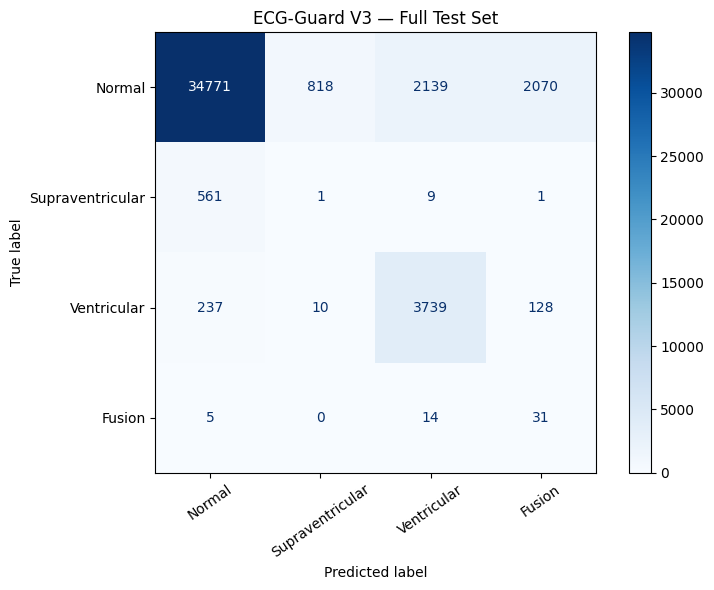

Classification report saved.


In [ ]:
# 11. CONFUSION MATRIX AND SAVE EVALUATION REPORTS

cm = confusion_matrix(
    y_test,
    y_test_calibrated,
    labels=[0, 1, 2, 3]
)

display(
    pd.DataFrame(
        cm,
        index=[f"Actual {name}" for name in CLASS_NAMES],
        columns=[f"Predicted {name}" for name in CLASS_NAMES]
    )
)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=35
)
ax.set_title("ECG-Guard V3 — Full Test Set")
plt.tight_layout()
plt.show()

report_dict = classification_report(
    y_test,
    y_test_calibrated,
    labels=[0, 1, 2, 3],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    OUTPUT_DIR / "ecg_guard_final_classification_report.csv"
)

print("Classification report saved.")


## Deployment export

The next cell creates a deployment folder in Google Drive containing:

- `ecg_guard_final.keras` — selected V3 model
- `deployment_config.json` — class names, input length and validation-selected calibration
- `demo_beats.npz` — one example waveform per class from the training set
- `test_metrics.json` — raw and calibrated full-test metrics

Copy these files into the Streamlit project as described in its README.


In [ ]:
# 12. EXPORT THE MODEL AND STREAMLIT DEPLOYMENT FILES

DEPLOY_DIR = OUTPUT_DIR / "streamlit_deployment"
DEPLOY_DIR.mkdir(parents=True, exist_ok=True)

# Save the selected model in the deployment folder
DEPLOY_MODEL_PATH = DEPLOY_DIR / "ecg_guard_final.keras"
best_model.save(str(DEPLOY_MODEL_PATH))

# Export one clearly labelled training example per class for app demonstration
demo_signals = []
demo_labels = []

for class_id in range(NUM_CLASSES):
    class_indices = np.where(y_train == class_id)[0]
    if len(class_indices) == 0:
        continue

    demo_signals.append(X_train[class_indices[0], :, 0])
    demo_labels.append(class_id)

np.savez_compressed(
    DEPLOY_DIR / "demo_beats.npz",
    signals=np.asarray(demo_signals, dtype=np.float32),
    labels=np.asarray(demo_labels, dtype=np.int32)
)

deployment_config = {
    "model_name": "ECG-Guard V3",
    "input_length": INPUT_LENGTH,
    "class_names": CLASS_NAMES,
    "calibration_alpha": SELECTED_ALPHA,
    "train_prior": train_prior.tolist(),
    "validation_prior": val_prior.tolist(),
    "prior_ratio": prior_ratio.tolist(),
    "raw_test_metrics": raw_test_metrics,
    "calibrated_test_metrics": calibrated_test_metrics,
    "test_samples": int(len(y_test)),
    "notes": (
        "Input must be an already-preprocessed, beat-segmented 77-sample "
        "waveform. Research prototype only; not for clinical diagnosis."
    )
}

with (DEPLOY_DIR / "deployment_config.json").open(
    "w", encoding="utf-8"
) as handle:
    json.dump(deployment_config, handle, indent=2)

with (DEPLOY_DIR / "test_metrics.json").open(
    "w", encoding="utf-8"
) as handle:
    json.dump(
        {
            "raw_test_metrics": raw_test_metrics,
            "calibrated_test_metrics": calibrated_test_metrics
        },
        handle,
        indent=2
    )

print("\n========== DEPLOYMENT EXPORT COMPLETE ==========")
print("Deployment folder:", DEPLOY_DIR)
for item in sorted(DEPLOY_DIR.iterdir()):
    print(item.name, f"({item.stat().st_size / (1024 * 1024):.2f} MB)")



========== DEPLOYMENT EXPORT COMPLETE ==========
Deployment folder: /content/drive/MyDrive/ECG_Guard_Dataset_V2/processed_v3/streamlit_deployment
demo_beats.npz (0.00 MB)
deployment_config.json (0.00 MB)
ecg_guard_final.keras (0.23 MB)
test_metrics.json (0.00 MB)


# Streamlit launch instructions

1. Download the Streamlit project ZIP supplied with this notebook.
2. Run the deployment export cell above in Google Colab.
3. Download `ecg_guard_final.keras`, `deployment_config.json`, and `demo_beats.npz` from the `streamlit_deployment` folder in Google Drive.
4. Put the model and demo file inside the Streamlit project's `models/` folder. Put `deployment_config.json` in the project root.
5. Install dependencies and launch:

```bash
pip install -r requirements.txt
streamlit run app.py
```

**Input limitation:** the app currently accepts an already-preprocessed beat with exactly 77 samples. It does not accept a raw 10-second ECG recording or WFDB `.dat/.hea` pair, because R-peak detection and raw-recording preprocessing are not part of the deployed model.

**Safety:** ECG-Guard is an academic prototype, not a medical device. A qualified clinician must interpret any real ECG.
